In [1]:
import sys
print(sys.prefix)

c:\Users\sawwa\OneDrive\Desktop\aircraft-damage-classification-captioning\.venv


In [2]:
import os 
import urllib.request
import tarfile


In [20]:
url =  "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/ZjXM4RKxlBK9__ZjHBLl5A/aircraft-damage-dataset-v1.tar"
data_dir = "../data"
tar_path = os.path.join(data_dir , "aircraft_damage_dataset_v1.tar")
dataset_dir = os.path.join(data_dir , "aircraft_damage_dataset_v1")

os.makedirs(data_dir, exist_ok = True)

if not os.path.exists(tar_path):
    print("Downloading dataset...")
    urllib.request.urlretrieve(url, tar_path)
    with tarfile.open(tar_path) as tar:
        tar.extractall(path=data_dir)
    print("Done")
    
else:
    print("Dataset already exists.")

Done


In [21]:
print("1. Notebook ရှိတဲ့နေရာ:", os.getcwd())
print("2. data_dir အစစ်အမှန်:", os.path.abspath(data_dir))
print("3. data_dir ရှိသလား:", os.path.exists(data_dir))
print("4. data_dir ထဲမှာ:", os.listdir(data_dir))

1. Notebook ရှိတဲ့နေရာ: c:\Users\sawwa\OneDrive\Desktop\aircraft-damage-classification-captioning\notebooks
2. data_dir အစစ်အမှန်: c:\Users\sawwa\OneDrive\Desktop\aircraft-damage-classification-captioning\data
3. data_dir ရှိသလား: True
4. data_dir ထဲမှာ: ['aircraft-damage-dataset-v1.tar', 'aircraft-damage-dataset_v1.tar', 'aircraft_damage_dataset_v1', 'aircraft_damage_dataset_v1.tar', 'processed', 'raw']


In [22]:
print(repr(dataset_dir))
print(os.path.exists(dataset_dir))

'../data\\aircraft_damage_dataset_v1'
True


In [23]:
print(os.listdir(dataset_dir))
print(os.listdir(os.path.join(dataset_dir, "train")))

['test', 'train', 'valid']
['crack', 'dent']


In [24]:
for split in ["train","valid","test"]:
    for cls in ['crack','dent']:
        folder = os.path.join(dataset_dir, split,cls)
        count = len(os.listdir(folder))
        print(f"{split:6} | {cls:6} | {count:3}")
        

train  | crack  | 150
train  | dent   | 150
valid  | crack  |  48
valid  | dent   |  48
test   | crack  |  25
test   | dent   |  25


crack (640, 640)
crack (640, 640)
dent (640, 640)
dent (640, 640)


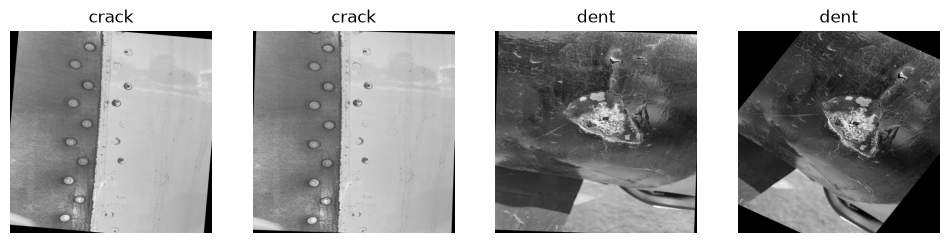

In [28]:
from PIL import Image
import matplotlib.pyplot as plt

train_dir = os.path.join(dataset_dir,"train")

crack_files = os.listdir(os.path.join(train_dir,"crack"))[:2]
dent_files = os.listdir(os.path.join(train_dir,"dent"))[:2]

samples = [("crack",f) for f in crack_files]+[("dent",f) for f in dent_files]

plt.figure(figsize=(12, 3))
for i , (cls,f) in enumerate(samples):
    img = Image.open(os.path.join(train_dir,cls,f))
    print(cls,img.size)
    plt.subplot(1,4,i+1)
    plt.imshow(img)
    plt.title(cls)
    plt.axis("off")
plt.show()
